In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Load All Datasets

In [2]:
student_info = pd.read_csv("studentInfo.csv", na_values='?')
student_info.head()

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass


In [3]:
student_registration = pd.read_csv("studentRegistration.csv", na_values='?')
student_registration.head()

,code_module,code_presentation,id_student,date_registration,date_unregistration
0,AAA,2013J,11391,-159.0,NaN
1,AAA,2013J,28400,-53.0,NaN
2,AAA,2013J,30268,-92.0,12.0
3,AAA,2013J,31604,-52.0,NaN
4,AAA,2013J,32885,-176.0,NaN


In [4]:
assessments = pd.read_csv("assessments.csv", na_values='?')
assessments.head()

,code_module,code_presentation,id_assessment,assessment_type,date,weight
0,AAA,2013J,1752,TMA,19.0,10.0
1,AAA,2013J,1753,TMA,54.0,20.0
2,AAA,2013J,1754,TMA,117.0,20.0
3,AAA,2013J,1755,TMA,166.0,20.0
4,AAA,2013J,1756,TMA,215.0,30.0


In [5]:
student_assessment = pd.read_csv("studentAssessment.csv", na_values='?')
student_assessment.head()

,id_assessment,id_student,date_submitted,is_banked,score
0,1752,11391,18,0,78.0
1,1752,28400,22,0,70.0
2,1752,31604,17,0,72.0
3,1752,32885,26,0,69.0
4,1752,38053,19,0,79.0


In [6]:
student_vle = pd.read_csv( "studentVle.csv", na_values='?',
usecols=["code_module", "code_presentation", "id_student", "id_site", "date", "sum_click"])
print(student_vle.shape)
student_vle.head()

(10655280, 6)


,code_module,code_presentation,id_student,id_site,date,sum_click
0,AAA,2013J,28400,546652,-10,4
1,AAA,2013J,28400,546652,-10,1
2,AAA,2013J,28400,546652,-10,1
3,AAA,2013J,28400,546614,-10,11
4,AAA,2013J,28400,546714,-10,1


In [7]:
courses = pd.read_csv("courses.csv", na_values='?')
courses.head()

,code_module,code_presentation,module_presentation_length
0,AAA,2013J,268
1,AAA,2014J,269
2,BBB,2013J,268
3,BBB,2014J,262
4,BBB,2013B,240


In [8]:
vle = pd.read_csv("vle.csv", na_values='?')
vle.head()

,id_site,code_module,code_presentation,activity_type,week_from,week_to
0,546943,AAA,2013J,resource,NaN,NaN
1,546712,AAA,2013J,oucontent,NaN,NaN
2,546998,AAA,2013J,resource,NaN,NaN
3,546888,AAA,2013J,url,NaN,NaN
4,547035,AAA,2013J,resource,NaN,NaN


In [9]:
CUTOFF_DAY = 90
KEY = ["code_module","code_presentation","id_student"]

### Target Column
   - 1 : Fail or Withdrawn
   - 0 : Pass or Distinction

In [10]:
student_info["final_result"].value_counts()

final_result
Pass           12361
Withdrawn      10156
Fail            7052
Distinction     3024
Name: count, dtype: int64

In [11]:
student_info["at_risk"] = 0
student_info.loc[student_info["final_result"] == "Fail", "at_risk"] = 1
student_info.loc[student_info["final_result"] == "Withdrawn", "at_risk"] = 1

In [12]:
student_info["at_risk"].value_counts()

at_risk
1    17208
0    15385
Name: count, dtype: int64

### Merging OR Feature Engineering

In [13]:
print("Student_info:",student_info.shape)
print("student_registration:",student_registration.shape)
print("Assessments:",assessments.shape)
print("student_assessment:",student_assessment.shape)
print("student_Vle:",student_vle.shape)
print("courses:",courses.shape)
print("Vle:",vle.shape)

Student_info: (32593, 13)
student_registration: (32593, 5)
Assessments: (206, 6)
student_assessment: (173912, 5)
student_Vle: (10655280, 6)
courses: (22, 3)
Vle: (6364, 6)


 - Merge Student_info and Student_registration

In [14]:
student_level_base = student_info.merge(student_registration, on=KEY, how="left")
print(student_level_base.shape)
student_level_base.head()

(32593, 15)


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result,at_risk,date_registration,date_unregistration
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass,0,-159.0,NaN
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass,0,-53.0,NaN
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn,1,-92.0,12.0
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass,0,-52.0,NaN
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass,0,-176.0,NaN


- Remove students who already left before day 90

In [15]:
print("Students before:", len(student_level_base))

Students before: 32593


In [16]:
still_studying = student_level_base["date_unregistration"].isna() | (student_level_base["date_unregistration"] > CUTOFF_DAY)
student_level_base = student_level_base[still_studying]
print("Students after :", len(student_level_base))
student_level_base.sample(5)

Students after : 25562


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result,at_risk,date_registration,date_unregistration
31976,GGG,2014J,612235,F,Scotland,HE Qualification,70-80%,35-55,0,30,N,Pass,0,-37.0,NaN
24395,FFF,2013J,484475,M,North Region,A Level or Equivalent,0-10%,0-35,0,60,N,Withdrawn,1,-30.0,101.0
15492,DDD,2013J,576368,M,South Region,Lower Than A Level,20-30%,0-35,0,60,N,Fail,1,-72.0,NaN
30216,GGG,2013J,528515,F,South West Region,Lower Than A Level,80-90%,35-55,0,30,N,Withdrawn,1,-59.0,228.0
31538,GGG,2014B,625930,F,East Midlands Region,Lower Than A Level,40-50%,35-55,0,30,N,Withdrawn,1,-45.0,103.0


- Student_Assessments and Assessments

In [17]:
student_assessment.sample(5)

,id_assessment,id_student,date_submitted,is_banked,score
56355,24293,597755,156,0,82.0
96761,30709,539063,32,0,91.0
33060,15012,567757,151,0,70.0
53224,24290,631455,234,0,98.0
107358,34862,549420,86,0,95.0


In [18]:
assessments.sample(5)

,code_module,code_presentation,id_assessment,assessment_type,date,weight
12,BBB,2013B,14991,CMA,54.0,1.0
175,FFF,2014J,34911,Exam,241.0,100.0
56,CCC,2014B,24288,CMA,137.0,8.0
9,AAA,2014J,1761,TMA,166.0,20.0
96,DDD,2014B,25356,TMA,53.0,12.5


In [19]:
s_a = student_assessment.merge(assessments, on="id_assessment", how="left")
s_a.sample(5)

,id_assessment,id_student,date_submitted,is_banked,score,code_module,code_presentation,assessment_type,date,weight
108671,34864,377274,165,0,89.0,FFF,2013B,TMA,166.0,25.0
99069,30714,594131,33,0,56.0,EEE,2014B,TMA,33.0,16.0
83752,25355,565158,22,0,84.0,DDD,2014B,TMA,25.0,10.0
31182,15010,185021,103,0,71.0,BBB,2014B,TMA,82.0,18.0
25806,15005,610802,133,0,60.0,BBB,2013J,CMA,131.0,1.0


In [20]:
s_a.shape

(173912, 10)

- Keep only work submitted up to day 90.  
- Remove rows with no score.

In [21]:
s_a = s_a[s_a["date_submitted"] <= CUTOFF_DAY]
s_a = s_a.dropna(subset=["score"])
s_a.shape

(70991, 10)

In [22]:
s_a.head()

,id_assessment,id_student,date_submitted,is_banked,score,code_module,code_presentation,assessment_type,date,weight
0,1752,11391,18,0,78.0,AAA,2013J,TMA,19.0,10.0
1,1752,28400,22,0,70.0,AAA,2013J,TMA,19.0,10.0
2,1752,31604,17,0,72.0,AAA,2013J,TMA,19.0,10.0
3,1752,32885,26,0,69.0,AAA,2013J,TMA,19.0,10.0
4,1752,38053,19,0,79.0,AAA,2013J,TMA,19.0,10.0


- "late" Column made, which shows 1 when date_submitted>date.


In [23]:
s_a["late"] = 0
s_a.loc[s_a["date_submitted"] > s_a["date"], "late"] = 1

- "wieghted_score" = score × weight ÷ 100 

In [24]:
s_a["weighted_score"] = (s_a["score"] * s_a["weight"]) / 100
s_a.sample(5)

,id_assessment,id_student,date_submitted,is_banked,score,code_module,code_presentation,assessment_type,date,weight,late,weighted_score
23526,15003,603446,56,0,100.0,BBB,2013J,CMA,54.0,1.0,1,1.000
3830,14984,515474,18,0,64.0,BBB,2013B,TMA,19.0,5.0,0,3.200
30933,15009,635435,39,0,71.0,BBB,2014B,TMA,40.0,18.0,0,12.780
85218,25357,599789,74,0,75.0,DDD,2014B,TMA,74.0,17.5,0,13.125
58473,24295,1490624,21,0,78.0,CCC,2014J,CMA,18.0,2.0,1,1.560


- "num_assessments_done" column create by adding same "id_assessments".

In [25]:
num_assessments_done = s_a.groupby(KEY)["id_assessment"].count().reset_index()
num_assessments_done = num_assessments_done.rename(columns={"id_assessment": "num_assessments_done"})
num_assessments_done.sample(5)

,code_module,code_presentation,id_student,num_assessments_done
10900,DDD,2013B,549698,6
836,BBB,2013B,295754,4
21006,FFF,2014B,560685,4
23015,FFF,2014J,674594,3
15933,EEE,2014B,29820,2


- "avg_score" of a student in all the assessments.

In [26]:
avg_score = s_a.groupby(KEY)["score"].mean().reset_index()
avg_score = avg_score.rename(columns={"score": "avg_score"})
avg_score.sample(5)

,code_module,code_presentation,id_student,avg_score
16919,EEE,2014J,648687,94.0
24479,GGG,2014B,160945,94.5
8109,CCC,2014B,2375259,40.0
20039,FFF,2013J,594800,85.5
4479,BBB,2014B,620427,88.6


- "min_score" of every student.

In [27]:
min_score = s_a.groupby(KEY)["score"].min().reset_index()
min_score = min_score.rename(columns={"score": "min_score"})
min_score.sample(5)

,code_module,code_presentation,id_student,min_score
8565,CCC,2014J,490313,48.0
25339,GGG,2014J,644105,55.0
16375,EEE,2014B,632459,81.0
6920,CCC,2014B,308918,50.0
22170,FFF,2014J,519115,54.0


- "weighted_score" by adding all assessments weighted score.

In [28]:
weighted_score = s_a.groupby(KEY)["weighted_score"].sum().reset_index()
weighted_score.head()

,code_module,code_presentation,id_student,weighted_score
0,AAA,2013J,11391,24.8
1,AAA,2013J,28400,20.6
2,AAA,2013J,31604,21.4
3,AAA,2013J,32885,12.9
4,AAA,2013J,38053,21.7


- "late_submissions" submit late summation.

In [29]:
late_submissions = s_a.groupby(KEY)["late"].sum().reset_index()
late_submissions = late_submissions.rename(columns={"late": "late_submissions"})
late_submissions.head()

,code_module,code_presentation,id_student,late_submissions
0,AAA,2013J,11391,0
1,AAA,2013J,28400,1
2,AAA,2013J,31604,0
3,AAA,2013J,32885,2
4,AAA,2013J,38053,1


- Keep only clicks up to day 90.

In [30]:
student_vle = student_vle[student_vle["date"] <= CUTOFF_DAY]
print(student_vle.shape)
student_vle.sample(5)

(5486878, 6)


,code_module,code_presentation,id_student,id_site,date,sum_click
1675854,BBB,2014J,589621,913502,78,1
5857228,EEE,2014J,687945,832565,-13,1
9386592,FFF,2014J,676600,882617,31,2
10288294,GGG,2013J,601199,661572,22,1
1540052,BBB,2014J,2436711,913468,9,3


- "total_clicks" by adding all click per students.

In [31]:
total_clicks = student_vle.groupby(KEY)["sum_click"].sum().reset_index()
total_clicks = total_clicks.rename(columns={"sum_click": "total_clicks"})
total_clicks.sample(5)

,code_module,code_presentation,id_student,total_clicks
2873,BBB,2013J,535833,50
20574,FFF,2013B,537151,95
17071,EEE,2013J,140060,887
15051,DDD,2014B,625427,1028
6623,BBB,2014J,676750,205


- "active_days" 

In [32]:
active_days = student_vle.groupby(KEY)["date"].nunique().reset_index()
active_days = active_days.rename(columns={"date": "active_days"})
active_days.head()

,code_module,code_presentation,id_student,active_days
0,AAA,2013J,11391,23
1,AAA,2013J,28400,36
2,AAA,2013J,30268,12
3,AAA,2013J,31604,51
4,AAA,2013J,32885,35


- "resources_visited"

In [33]:
# resources_visited = student_vle.groupby(KEY)["id_site"].nunique().reset_index()
# resources_visited = resources_visited.rename(columns={"id_site": "resources_visited"})
# resources_visited.head()

In [34]:
recent_vle = student_vle[student_vle["date"] > CUTOFF_DAY - 30]
clicks_last_30_days = recent_vle.groupby(KEY)["sum_click"].sum().reset_index()
clicks_last_30_days = clicks_last_30_days.rename(columns={"sum_click": "clicks_last_30_days"})
clicks_last_30_days.sample(5)

,code_module,code_presentation,id_student,clicks_last_30_days
4642,BBB,2014J,619935,9
680,BBB,2013B,187793,304
15846,FFF,2013B,552987,496
16025,FFF,2013B,1536138,144
15402,FFF,2013B,515844,209


### 5. Join All Features.

In [35]:
data = student_level_base.copy()

In [36]:
data = data.merge(num_assessments_done, on=KEY, how="left")
data = data.merge(avg_score, on=KEY, how="left")
data = data.merge(min_score, on=KEY, how="left")
data = data.merge(weighted_score, on=KEY, how="left")
data = data.merge(late_submissions, on=KEY, how="left")
data = data.merge(total_clicks, on=KEY, how="left")
data = data.merge(active_days, on=KEY, how="left")
# data = data.merge(resources_visited, on=KEY, how="left")
data = data.merge(clicks_last_30_days, on=KEY, how="left")

In [37]:
data.columns.tolist()

['code_module',
 'code_presentation',
 'id_student',
 'gender',
 'region',
 'highest_education',
 'imd_band',
 'age_band',
 'num_of_prev_attempts',
 'studied_credits',
 'disability',
 'final_result',
 'at_risk',
 'date_registration',
 'date_unregistration',
 'num_assessments_done',
 'avg_score',
 'min_score',
 'weighted_score',
 'late_submissions',
 'total_clicks',
 'active_days',
 'clicks_last_30_days']

### EDA

In [38]:
print(data.shape)
data.sample(5)

(25562, 23)


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,...,date_registration,date_unregistration,num_assessments_done,avg_score,min_score,weighted_score,late_submissions,total_clicks,active_days,clicks_last_30_days
19382,FFF,2013J,580842,F,South Region,Lower Than A Level,90-100%,35-55,0,90,...,-42.0,NaN,5.0,88.000000,80.0,20.00,0.0,3408.0,86.0,660.0
10311,DDD,2013B,515945,M,London Region,A Level or Equivalent,80-90%,0-35,0,60,...,-23.0,NaN,6.0,91.000000,76.0,33.82,3.0,630.0,53.0,53.0
25307,GGG,2014J,677025,F,South Region,Lower Than A Level,90-100%,35-55,0,30,...,-81.0,NaN,2.0,85.000000,70.0,0.00,0.0,93.0,8.0,35.0
10746,DDD,2013B,2082180,M,London Region,A Level or Equivalent,90-100%,0-35,1,60,...,-67.0,115.0,5.0,78.200000,17.0,15.55,3.0,221.0,13.0,9.0
14634,DDD,2014J,2542116,M,Scotland,HE Qualification,0-10%,35-55,0,60,...,-99.0,NaN,3.0,93.333333,90.0,23.25,0.0,794.0,64.0,115.0


In [39]:
print(data.info())

<class 'pandas.DataFrame'>
RangeIndex: 25562 entries, 0 to 25561
Data columns (total 23 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   code_module           25562 non-null  str    
 1   code_presentation     25562 non-null  str    
 2   id_student            25562 non-null  int64  
 3   gender                25562 non-null  str    
 4   region                25562 non-null  str    
 5   highest_education     25562 non-null  str    
 6   imd_band              24589 non-null  str    
 7   age_band              25562 non-null  str    
 8   num_of_prev_attempts  25562 non-null  int64  
 9   studied_credits       25562 non-null  int64  
 10  disability            25562 non-null  str    
 11  final_result          25562 non-null  str    
 12  at_risk               25562 non-null  int64  
 13  date_registration     25555 non-null  float64
 14  date_unregistration   3041 non-null   float64
 15  num_assessments_done  23836 no

In [40]:
data.duplicated().sum()

np.int64(0)

In [41]:
data.describe()

,id_student,num_of_prev_attempts,studied_credits,at_risk,date_registration,date_unregistration,num_assessments_done,avg_score,min_score,weighted_score,late_submissions,total_clicks,active_days,clicks_last_30_days
count,2.556200e+04,25562.000000,25562.000000,25562.000000,25555.000000,3041.000000,23836.000000,23836.000000,23836.000000,23836.000000,23836.000000,25061.000000,25061.000000,21744.000000
mean,7.068977e+05,0.158556,75.384164,0.398130,-65.724985,153.738902,2.854674,75.293497,65.974702,20.005772,0.743413,731.995651,33.464586,153.844463
std,5.526390e+05,0.470331,37.377960,0.489522,47.303216,41.012068,1.316985,16.254962,20.414453,12.705868,0.990424,855.074658,23.075731,210.999711
min,6.516000e+03,0.000000,30.000000,0.000000,-311.000000,91.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000
25%,5.058552e+05,0.000000,60.000000,0.000000,-94.000000,118.000000,2.000000,67.787500,57.000000,9.990000,0.000000,205.000000,15.000000,34.000000
50%,5.889670e+05,0.000000,60.000000,0.000000,-52.000000,151.000000,3.000000,79.000000,70.000000,18.750000,0.000000,460.000000,29.000000,84.000000
75%,6.409235e+05,0.000000,90.000000,1.000000,-29.000000,180.000000,3.000000,86.750000,80.000000,30.500000,1.000000,941.000000,48.000000,185.000000
max,2.710343e+06,6.000000,630.000000,1.000000,167.000000,444.000000,12.000000,100.000000,100.000000,90.960000,6.000000,12783.000000,115.000000,4715.000000


In [42]:
data.describe(exclude='number')

,code_module,code_presentation,gender,region,highest_education,imd_band,age_band,disability,final_result
count,25562,25562,25562,25562,25562,24589,25562,25562,25562
unique,7,4,2,13,5,10,3,2,4
top,FFF,2014J,M,Scotland,A Level or Equivalent,30-40%,0-35,N,Pass
freq,6105,8533,13987,2950,11295,2786,17773,23210,12361


In [43]:
data.isnull().sum()

code_module                 0
code_presentation           0
id_student                  0
gender                      0
region                      0
highest_education           0
imd_band                  973
age_band                    0
num_of_prev_attempts        0
studied_credits             0
disability                  0
final_result                0
at_risk                     0
date_registration           7
date_unregistration     22521
num_assessments_done     1726
avg_score                1726
min_score                1726
weighted_score           1726
late_submissions         1726
total_clicks              501
active_days               501
clicks_last_30_days      3818
dtype: int64

<Axes: xlabel='at_risk', ylabel='count'>

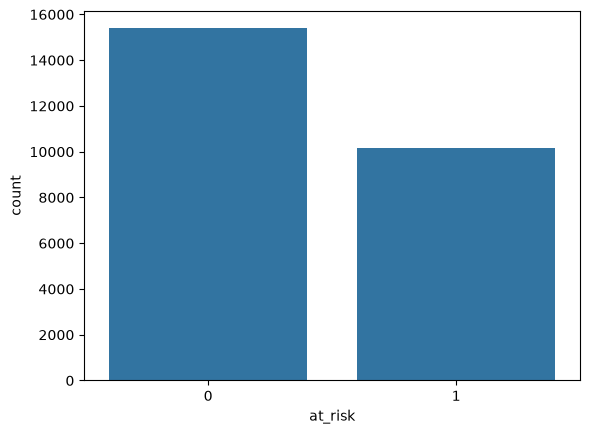

In [44]:
sns.countplot(x='at_risk', data=data)

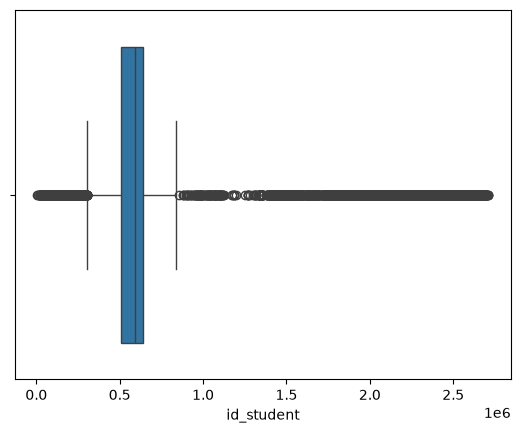

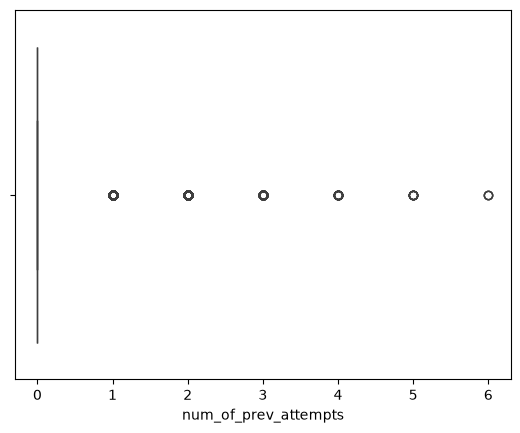

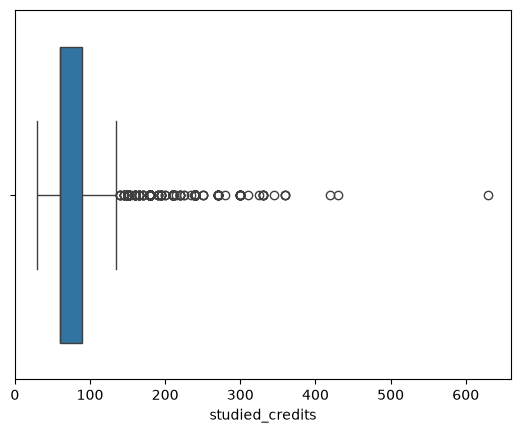

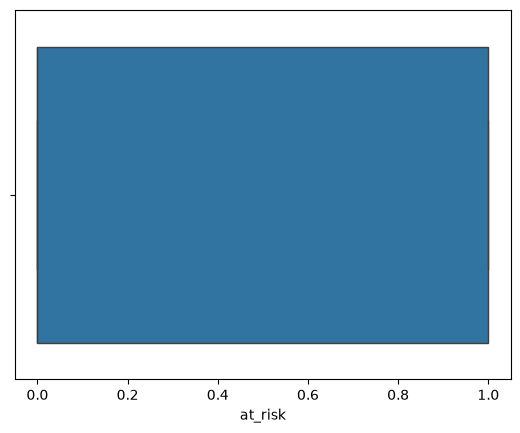

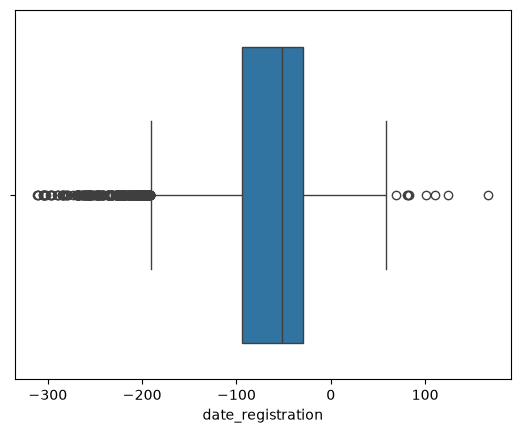

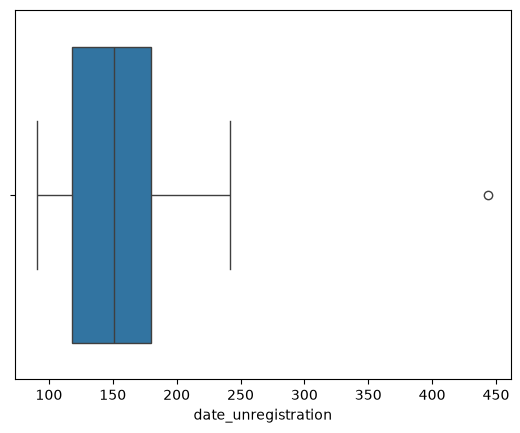

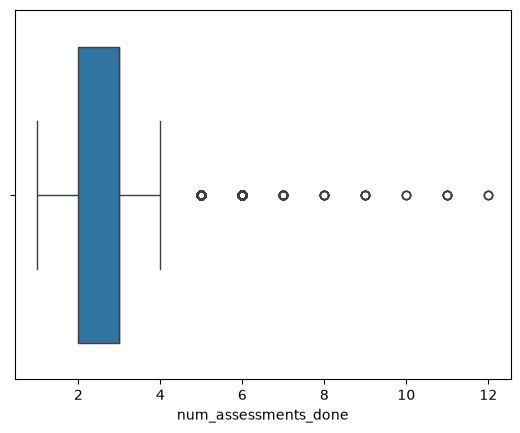

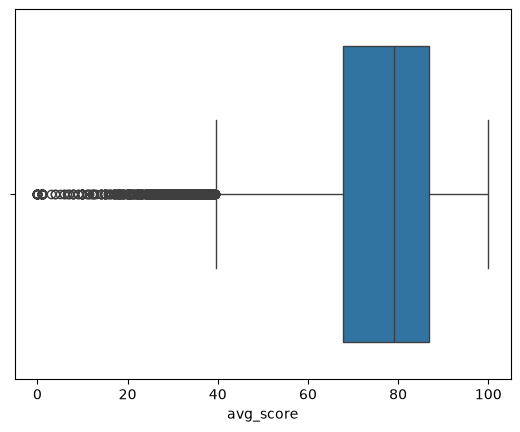

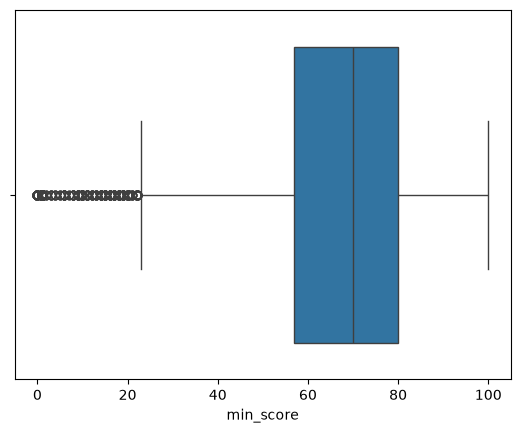

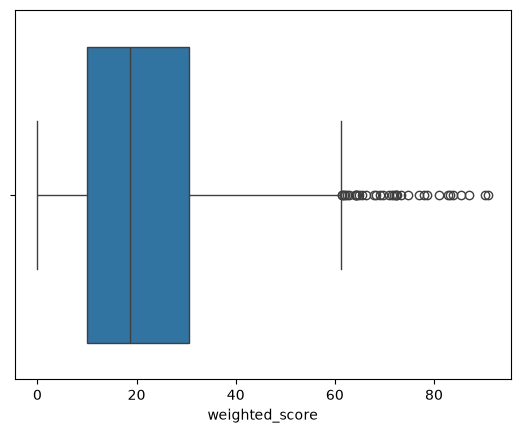

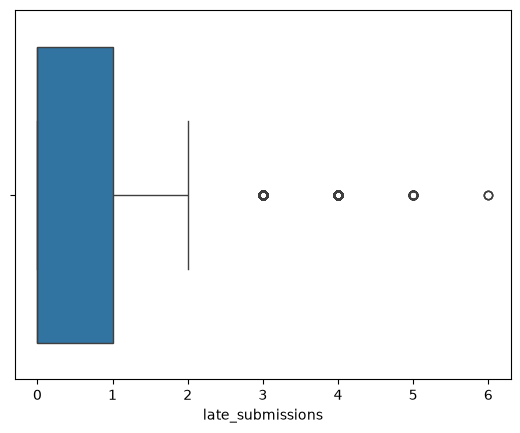

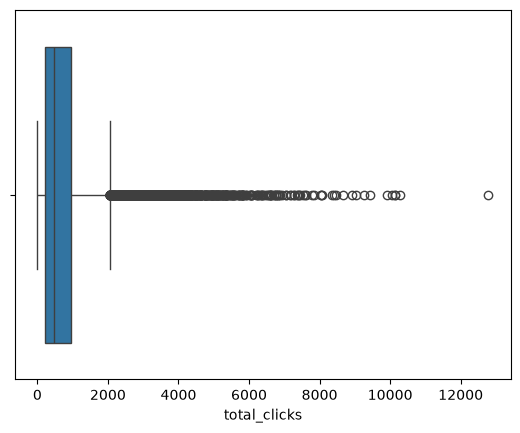

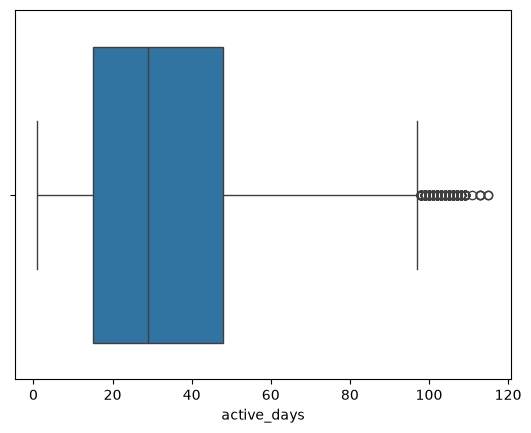

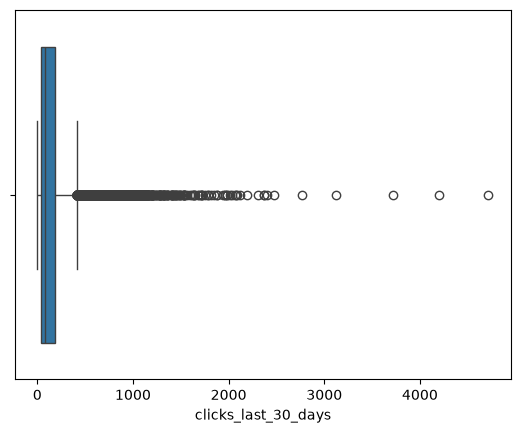

In [45]:
numerical_cols = data.select_dtypes(include=np.number).columns

for i in numerical_cols:
  sns.boxplot(x=data[i])
  plt.show()


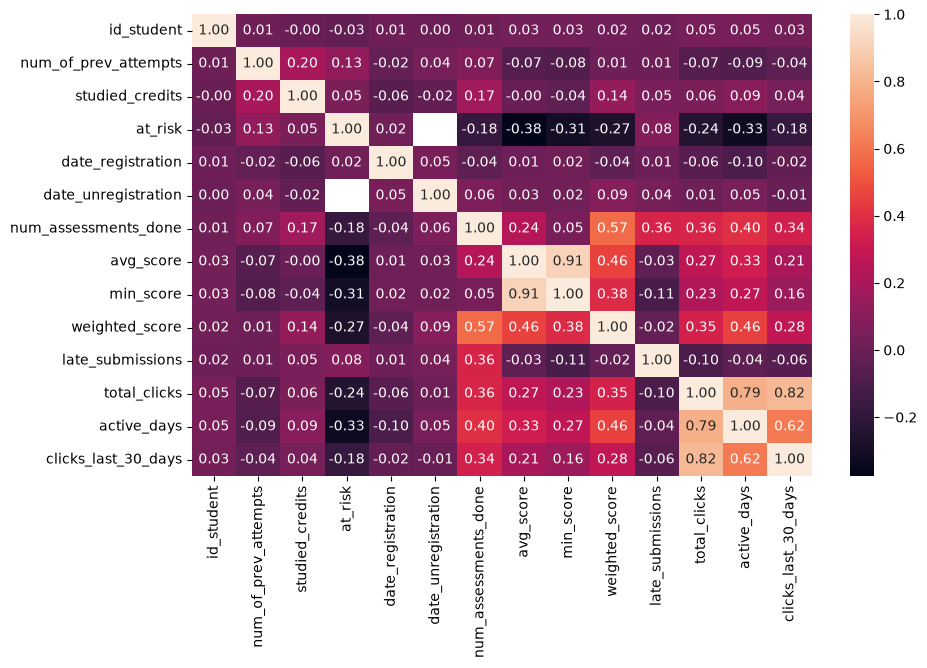

In [46]:
plt.figure(figsize=(10,6))
sns.heatmap(data.corr(numeric_only=True), annot=True,fmt='.2f')
plt.show()

### 6. Clean The Data

In [47]:
data[data['num_assessments_done'].isnull()].head()

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,...,date_registration,date_unregistration,num_assessments_done,avg_score,min_score,weighted_score,late_submissions,total_clicks,active_days,clicks_last_30_days
76,AAA,2013J,195262,M,London Region,A Level or Equivalent,90-100%,0-35,0,60,...,-45.0,185.0,NaN,NaN,NaN,NaN,NaN,777.0,23.0,121.0
112,AAA,2013J,281589,M,North Western Region,HE Qualification,30-40%,0-35,0,60,...,-50.0,NaN,NaN,NaN,NaN,NaN,NaN,54.0,7.0,NaN
158,AAA,2013J,346843,F,Scotland,HE Qualification,50-60%,35-55,0,120,...,-44.0,NaN,NaN,NaN,NaN,NaN,NaN,164.0,8.0,NaN
195,AAA,2013J,494424,F,North Region,A Level or Equivalent,80-90%,0-35,0,60,...,-38.0,NaN,NaN,NaN,NaN,NaN,NaN,58.0,2.0,NaN
324,AAA,2013J,2569324,M,South Region,A Level or Equivalent,90-100%,0-35,0,120,...,-81.0,93.0,NaN,NaN,NaN,NaN,NaN,26.0,3.0,1.0


- These Five columns have same null value and filled by 0.

In [48]:

cols1 = ['num_assessments_done','avg_score','late_submissions','weighted_score','min_score']#
print(data[cols1].isnull().sum())
print(data[cols1].isnull().all(axis=1).sum())


num_assessments_done    1726
avg_score               1726
late_submissions        1726
weighted_score          1726
min_score               1726
dtype: int64
1726


In [49]:

data[cols1] = data[cols1].fillna(0)

In [50]:
data[data['total_clicks'].isnull()].sample(5)

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,...,date_registration,date_unregistration,num_assessments_done,avg_score,min_score,weighted_score,late_submissions,total_clicks,active_days,clicks_last_30_days
23989,GGG,2013J,608114,M,East Anglian Region,A Level or Equivalent,40-50%,0-35,0,30,...,-28.0,NaN,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN
25087,GGG,2014J,639995,F,South West Region,Lower Than A Level,60-70%,35-55,0,30,...,3.0,135.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN
23703,GGG,2013J,591814,F,West Midlands Region,Lower Than A Level,60-70%,0-35,0,30,...,-36.0,NaN,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN
24382,GGG,2014B,612459,F,North Western Region,Lower Than A Level,0-10%,0-35,0,30,...,-75.0,NaN,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN
5983,BBB,2014J,651778,M,West Midlands Region,Lower Than A Level,10-20,0-35,0,60,...,-136.0,NaN,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN


In [51]:
cols2 = ["total_clicks","active_days"]
print(data[cols2].isnull().sum())
print(data[cols2].isnull().all(axis=1).sum())

total_clicks    501
active_days     501
dtype: int64
501


In [52]:
data[cols2] = data[cols2].fillna(0)

In [53]:
data['clicks_last_30_days'] = data['clicks_last_30_days'].fillna(0)


In [54]:
data[data['imd_band'].isnull()].head()

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,...,date_registration,date_unregistration,num_assessments_done,avg_score,min_score,weighted_score,late_submissions,total_clicks,active_days,clicks_last_30_days
8,AAA,2013J,53025,M,North Region,Post Graduate Qualification,NaN,55<=,0,60,...,-179.0,NaN,2.0,75.5,71.0,23.1,0.0,1242.0,55.0,404.0
16,AAA,2013J,71361,M,Ireland,HE Qualification,NaN,35-55,0,60,...,-130.0,NaN,2.0,84.0,82.0,25.4,0.0,1536.0,60.0,132.0
26,AAA,2013J,104476,M,Ireland,Post Graduate Qualification,NaN,35-55,0,60,...,-109.0,NaN,2.0,81.5,78.0,24.1,2.0,1823.0,55.0,299.0
32,AAA,2013J,114017,F,North Region,Post Graduate Qualification,NaN,35-55,0,60,...,-29.0,NaN,2.0,71.0,66.0,21.8,0.0,484.0,21.0,5.0
61,AAA,2013J,172112,M,Ireland,HE Qualification,NaN,35-55,0,60,...,-50.0,NaN,2.0,63.5,60.0,19.4,1.0,507.0,41.0,105.0


In [55]:
data["imd_band"] = data["imd_band"].fillna("unknown")
data["imd_band"] = data["imd_band"].str.replace("%", "", regex=False)
data["imd_band"].value_counts()

imd_band
30-40      2786
20-30      2731
10-20      2614
50-60      2504
40-50      2503
0-10       2423
70-80      2351
60-70      2342
80-90      2235
90-100     2100
unknown     973
Name: count, dtype: int64

In [56]:
data['date_registration'] = data['date_registration'].fillna(data['date_registration'].median())

In [57]:
data['has_unregistration'] = (data['date_unregistration'].notna().astype(int))
data['has_unregistration'].value_counts()

has_unregistration
0    22521
1     3041
Name: count, dtype: int64

In [58]:
data['date_unregistration'] = data['date_unregistration'].fillna(0)

In [59]:
data.isnull().sum()

code_module             0
code_presentation       0
id_student              0
gender                  0
region                  0
highest_education       0
imd_band                0
age_band                0
num_of_prev_attempts    0
studied_credits         0
disability              0
final_result            0
at_risk                 0
date_registration       0
date_unregistration     0
num_assessments_done    0
avg_score               0
min_score               0
weighted_score          0
late_submissions        0
total_clicks            0
active_days             0
clicks_last_30_days     0
has_unregistration      0
dtype: int64

- Separate Feature Columns 


In [60]:
num_cols = data.select_dtypes(include="number").columns.tolist()
cat_cols = data.select_dtypes(include="str").columns.tolist()
print(num_cols)
print(cat_cols)

['id_student', 'num_of_prev_attempts', 'studied_credits', 'at_risk', 'date_registration', 'date_unregistration', 'num_assessments_done', 'avg_score', 'min_score', 'weighted_score', 'late_submissions', 'total_clicks', 'active_days', 'clicks_last_30_days', 'has_unregistration']
['code_module', 'code_presentation', 'gender', 'region', 'highest_education', 'imd_band', 'age_band', 'disability', 'final_result']


In [61]:
# num_cols = ['id_student', 'num_of_prev_attempts', 'studied_credits', 'at_risk', 'date_registration', 'date_unregistration', 'num_assessments_done', 'avg_score', 'min_score', 'late_submissions', 'active_days', 'clicks_last_30_days', 'has_unregistration',"total_clicks"]
# cat_cols = ['code_module', 'code_presentation', 'gender', 'region', 'highest_education', 'imd_band', 'age_band', 'disability', 'final_result']

- New feature: average clicks per day = (total clicks ÷ active days)

In [62]:
data["avg_clicks_per_day"] = data["total_clicks"] / data["active_days"]
data["avg_clicks_per_day"]=data["avg_clicks_per_day"].fillna(0)

In [63]:
num_cols.append("avg_clicks_per_day")
print(num_cols)

['id_student', 'num_of_prev_attempts', 'studied_credits', 'at_risk', 'date_registration', 'date_unregistration', 'num_assessments_done', 'avg_score', 'min_score', 'weighted_score', 'late_submissions', 'total_clicks', 'active_days', 'clicks_last_30_days', 'has_unregistration', 'avg_clicks_per_day']


### EDA

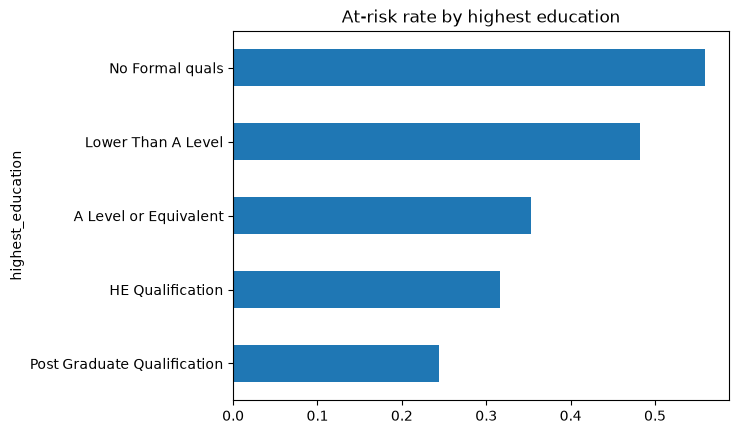

In [64]:
data.groupby("highest_education")["at_risk"].mean().sort_values().plot(kind="barh")
plt.title("At-risk rate by highest education")
plt.show()

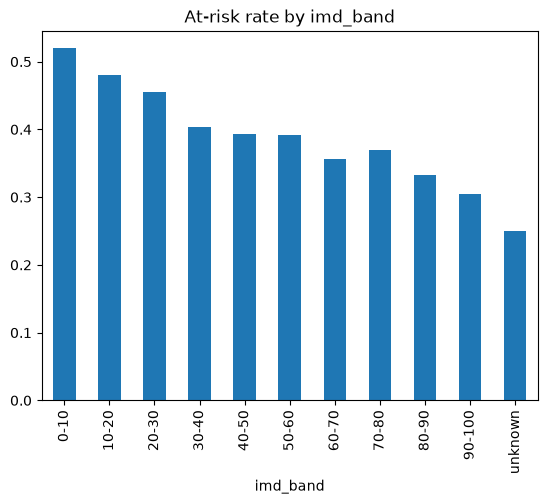

In [65]:
data.groupby("imd_band")["at_risk"].mean().plot(kind="bar")
plt.title("At-risk rate by imd_band")
plt.show()

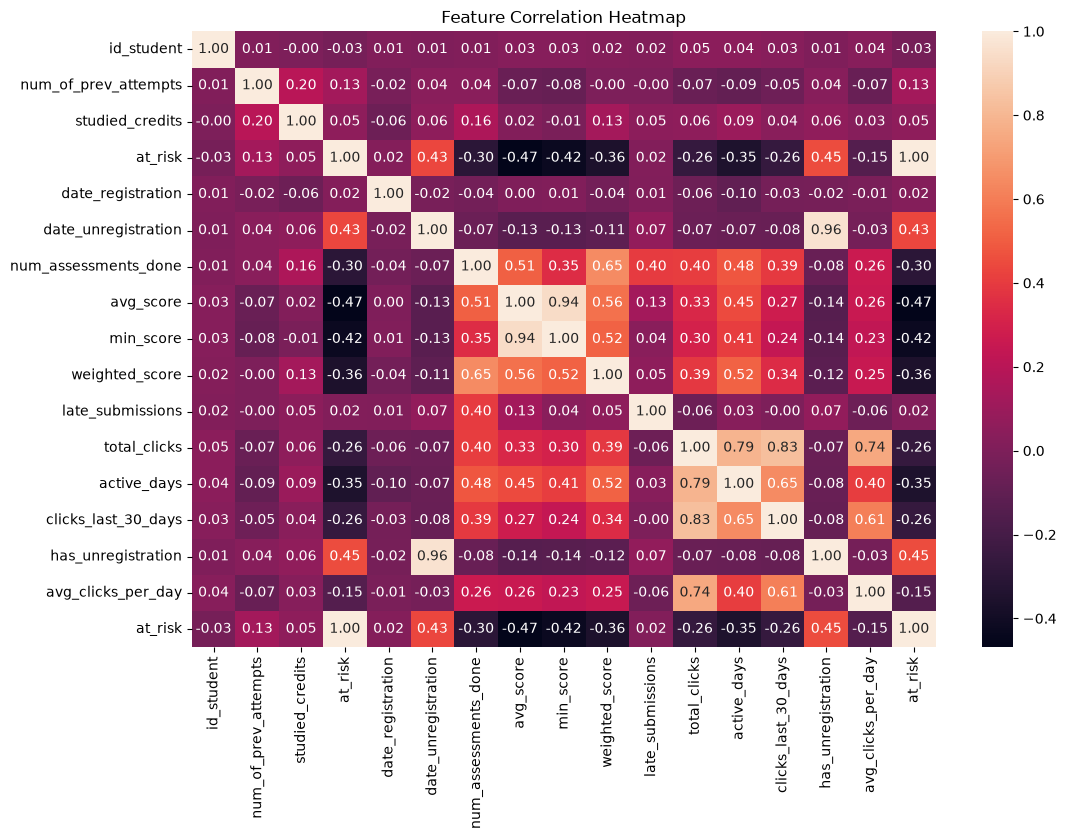

In [66]:
corr_matrix = data[num_cols+['at_risk']].corr(numeric_only=True)
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f')
plt.title("Feature Correlation Heatmap")
plt.show()

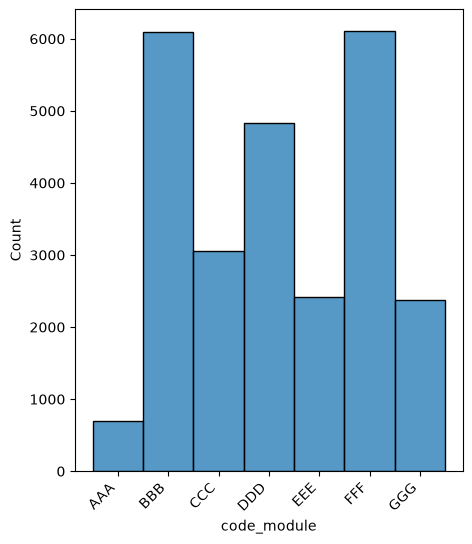

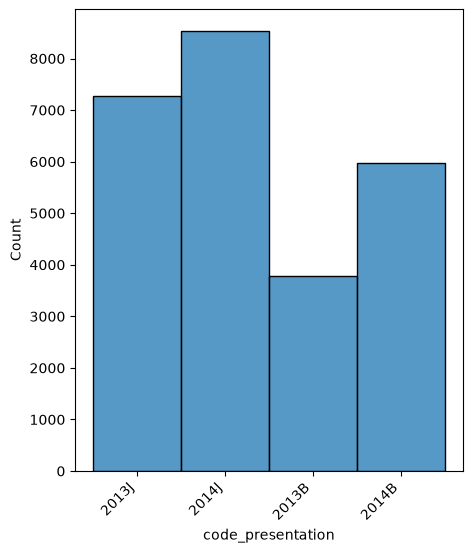

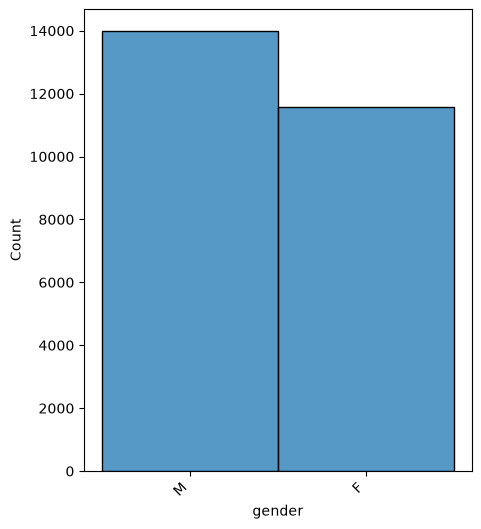

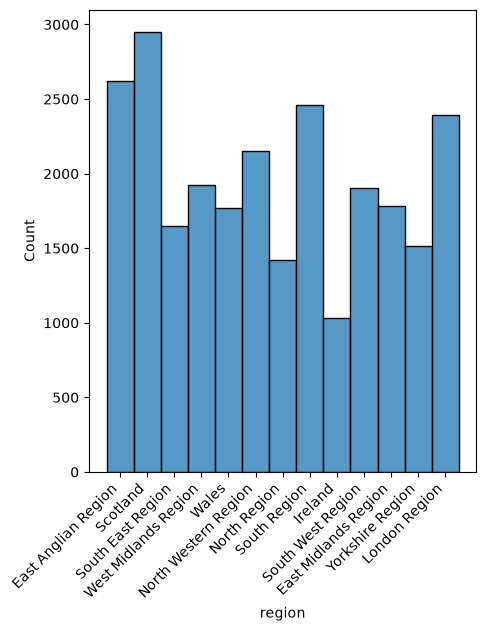

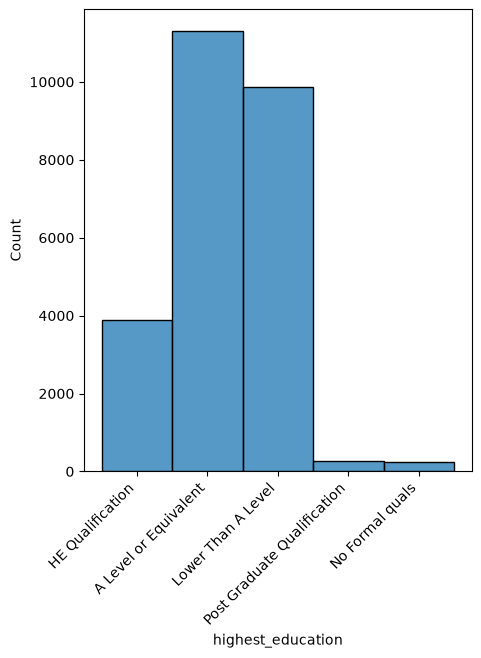

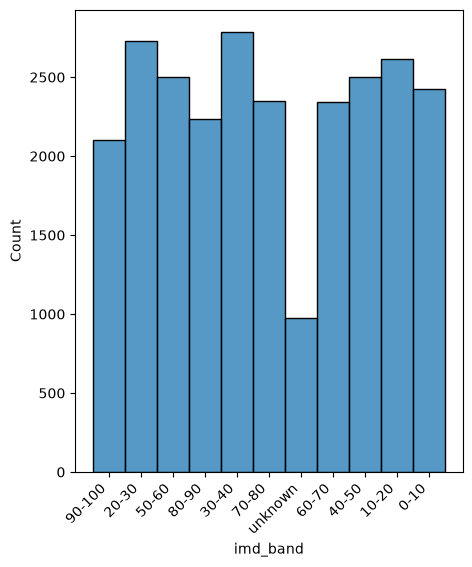

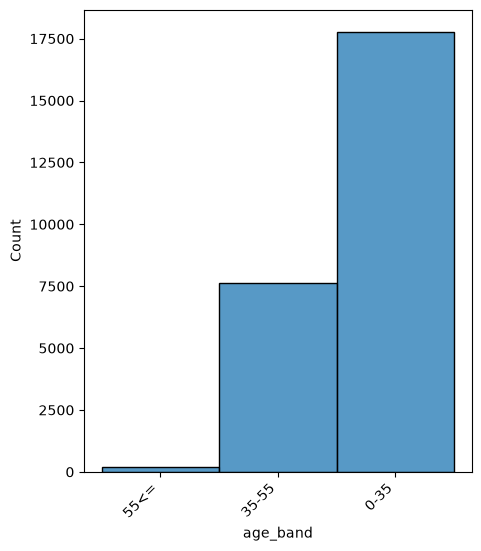

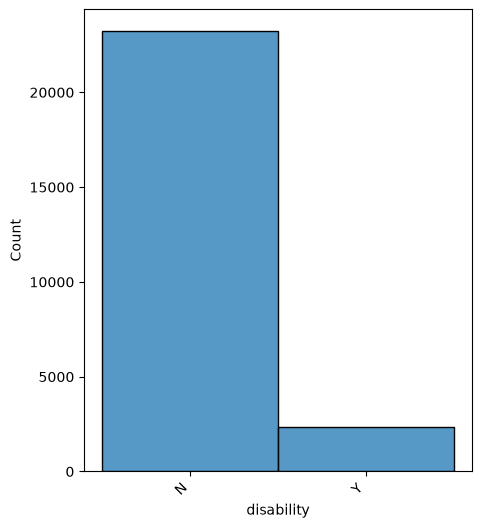

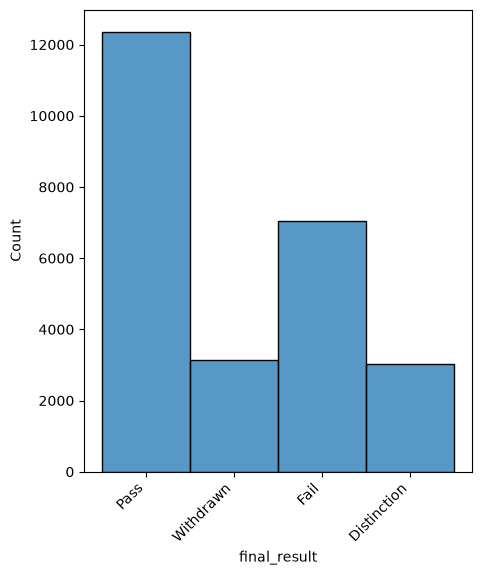

In [67]:
for i in cat_cols:
    plt.figure(figsize=(5,6))
    plt.xticks(rotation=45,ha='right')
    sns.histplot(data[i])

- Avg_score vs at_risk (boxplot)

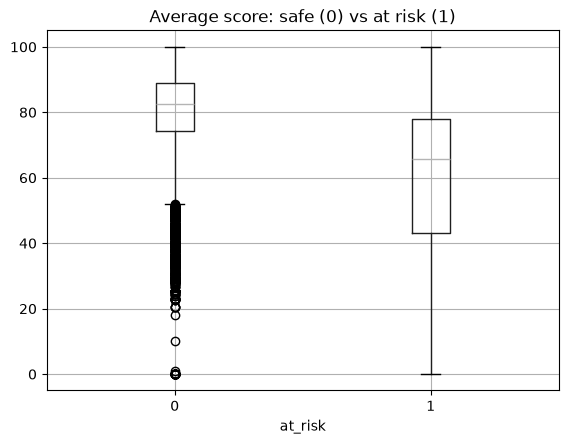

In [68]:
data.boxplot(column="avg_score", by="at_risk")
plt.title("Average score: safe (0) vs at risk (1)")
plt.suptitle("")
plt.show()

- total_clicks vs at_risk (boxplot)

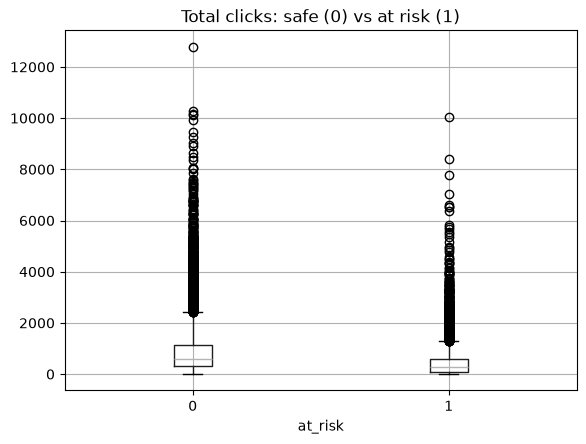

In [69]:
data.boxplot(column="total_clicks", by="at_risk")
plt.title("Total clicks: safe (0) vs at risk (1)")
plt.suptitle("")
plt.show()

- active_days vs at_risk

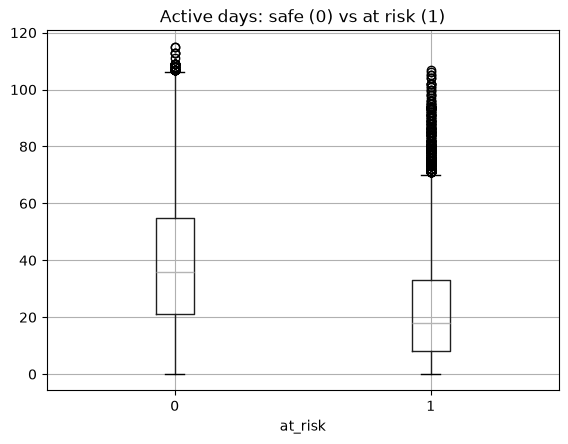

In [70]:
data.boxplot(column="active_days", by="at_risk")
plt.title("Active days: safe (0) vs at risk (1)")
plt.suptitle("")
plt.show()

- weighted_score vs at_risk

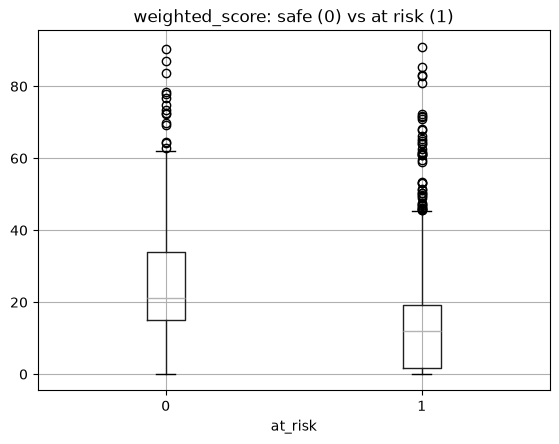

In [71]:
data.boxplot(column="weighted_score", by="at_risk")
plt.title("weighted_score: safe (0) vs at risk (1)")
plt.suptitle("")
plt.show()

- OutLiers

In [72]:
num_features = data[num_cols].select_dtypes(include='number') #int64 or float64
Q1  = num_features.quantile(0.25)
Q3  = num_features.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = (num_features < lower_bound) | (num_features > upper_bound)
print(outliers.sum())

id_student              5165
num_of_prev_attempts    3198
studied_credits         1274
at_risk                    0
date_registration        372
date_unregistration     3041
num_assessments_done    4844
avg_score               2215
min_score               2622
weighted_score            32
late_submissions        1529
total_clicks            1754
active_days              262
clicks_last_30_days     2299
has_unregistration      3041
avg_clicks_per_day       981
dtype: int64


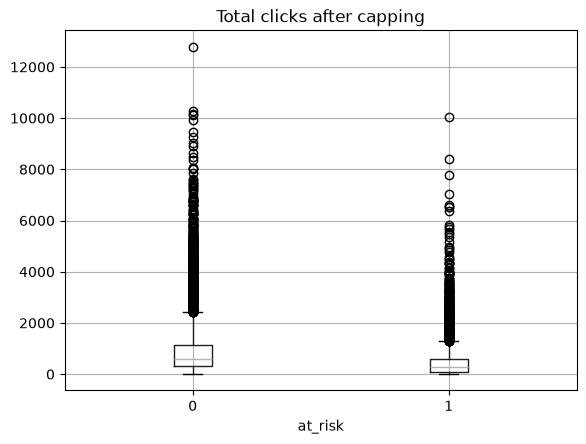

In [73]:
data.boxplot(column="total_clicks", by="at_risk")
plt.title("Total clicks after capping")
plt.suptitle("")
plt.show()

In [74]:
data["num_of_prev_attempts"].value_counts()

num_of_prev_attempts
0    22364
1     2538
2      519
3      102
4       27
5        9
6        3
Name: count, dtype: int64

In [75]:
data.columns.tolist()

['code_module',
 'code_presentation',
 'id_student',
 'gender',
 'region',
 'highest_education',
 'imd_band',
 'age_band',
 'num_of_prev_attempts',
 'studied_credits',
 'disability',
 'final_result',
 'at_risk',
 'date_registration',
 'date_unregistration',
 'num_assessments_done',
 'avg_score',
 'min_score',
 'weighted_score',
 'late_submissions',
 'total_clicks',
 'active_days',
 'clicks_last_30_days',
 'has_unregistration',
 'avg_clicks_per_day']

In [76]:
data = data.drop(['final_result','id_student','date_unregistration','has_unregistration','date_registration','studied_credits','code_module',
'code_presentation','imd_band','gender','disability','age_band','region','highest_education','num_of_prev_attempts','total_clicks','clicks_last_30_days','avg_clicks_per_day'],axis=1)
data

,at_risk,num_assessments_done,avg_score,min_score,weighted_score,late_submissions,active_days
0,0,2.0,81.5,78.0,24.8,0.0,23.0
1,0,2.0,69.0,68.0,20.6,1.0,36.0
2,0,2.0,71.5,71.0,21.4,0.0,51.0
3,0,2.0,49.5,30.0,12.9,2.0,35.0
4,0,2.0,74.0,69.0,21.7,1.0,58.0
...,...,...,...,...,...,...,...
25557,1,0.0,0.0,0.0,0.0,0.0,5.0
25558,0,1.0,80.0,80.0,0.0,1.0,8.0
25559,0,1.0,65.0,65.0,0.0,0.0,5.0
25560,1,2.0,91.5,83.0,0.0,0.0,11.0


In [77]:
# df_encoded = pd.get_dummies(data,columns=['age_band','region','highest_education'],drop_first=True)
# # df_encoded=df_encoded.drop(['final_result','id_student','date_unregistration','has_unregistration','date_registration'],axis=1)
# print(df_encoded.dtypes)
# print(df_encoded.shape)

### 8. Choose X and Y

In [78]:

X = data.drop('at_risk',axis=1)
y = data["at_risk"]

In [79]:
print("X shape:", X.shape)
print("y shape:", y.shape)
X.sample(5)

X shape: (25562, 6)
y shape: (25562,)


,num_assessments_done,avg_score,min_score,weighted_score,late_submissions,active_days
22108,2.0,89.0,88.0,22.25,0.0,48.0
15717,2.0,87.5,87.0,38.44,0.0,80.0
23705,1.0,45.0,45.0,0.00,0.0,9.0
25485,2.0,87.5,75.0,0.00,0.0,42.0
16621,2.0,84.5,76.0,36.16,0.0,34.0


- Split into train and test
- Train set (80%)
- Test set (20%)
- stratify=y keeps the same ratio of at-risk students in both sets.

In [80]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, stratify=y, random_state=42)
print("Train rows:", len(X_train))
print("Test rows :", len(X_test))

Train rows: 20449
Test rows : 5113


- Upper Limit Capping 

In [81]:
# cap_cols = ["clicks_last_30_days","total_clicks"]
# caps = X_train[cap_cols].quantile(0.99)
# print("Upper limits:")
# print(caps)

In [82]:
# X_train = X_train.copy()
# X_test = X_test.copy()
# X_train[cap_cols] = X_train[cap_cols].clip(upper=caps, axis=1)
# X_test[cap_cols] = X_test[cap_cols].clip(upper=caps, axis=1)

In [83]:
# print("Training maximum values:")
# print(X_train[cap_cols].max())
# print("\nTest maximum values:")
# print(X_test[cap_cols].max())
# print("\nLearned upper limits:")
# print(caps)

- Train Models

In [84]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

models = {
    "Logistic Regression": Pipeline([("scaler",StandardScaler()),
                                     ("model", LogisticRegression(max_iter=2000,random_state=42))]),
    "KNN": Pipeline([("scaler",StandardScaler()),
                     ("model",KNeighborsClassifier(n_neighbors=5))]),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    "xgb_model" : XGBClassifier(n_estimators=200,learning_rate=0.05,max_depth=5,random_state=42,eval_metric='logloss')
}

In [85]:
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_score

results = []
scoring = {'accuracy':'accuracy','precision':'precision',  'recall':'recall',  'f1':'f1','roc_auc':'roc_auc'}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for name, model in models.items():
   cv_results = cross_validate(model, X_train,y_train,cv=cv,scoring=scoring, n_jobs=-1)
   model.fit(X_train, y_train)
   test_probs = model.predict_proba(X_test)[:, 1]
   predictions = model.predict(X_test)
   results.append({
        "Model": name,
        "CV_Accuracy": cv_results["test_accuracy"].mean(),
        "CV_Precision": cv_results["test_precision"].mean(),
        "CV_Recall": cv_results["test_recall"].mean(),
        "CV_F1": cv_results["test_f1"].mean(),
        "CV_ROC_AUC": cv_results["test_roc_auc"].mean(),

        "Test_Accuracy": accuracy_score(y_test, predictions),
        "Test_Precision": precision_score(y_test, predictions, zero_division=0),
        "Test_Recall": recall_score(y_test, predictions, zero_division=0),
        "Test_F1": f1_score(y_test, predictions, zero_division=0),
        "ROC_AUC":roc_auc_score(y_test,test_probs)   
        })

In [86]:
results_df = pd.DataFrame(results)
results_df = results_df.sort_values("CV_F1", ascending=False)
display(results_df.round(4))

,Model,CV_Accuracy,CV_Precision,CV_Recall,CV_F1,CV_ROC_AUC,Test_Accuracy,Test_Precision,Test_Recall,Test_F1,ROC_AUC
4,xgb_model,0.7842,0.7978,0.6137,0.6937,0.8412,0.7858,0.8014,0.6144,0.6956,0.8475
3,Random Forest,0.7645,0.7364,0.6362,0.6826,0.8204,0.7647,0.7381,0.6341,0.6822,0.8206
1,KNN,0.7571,0.7262,0.6258,0.6723,0.7978,0.7587,0.7329,0.6198,0.6716,0.8014
2,Decision Tree,0.7684,0.7888,0.5716,0.6627,0.8181,0.7716,0.7960,0.5732,0.6665,0.8257
0,Logistic Regression,0.7273,0.7208,0.5143,0.6003,0.7945,0.7264,0.7195,0.5128,0.5988,0.7950


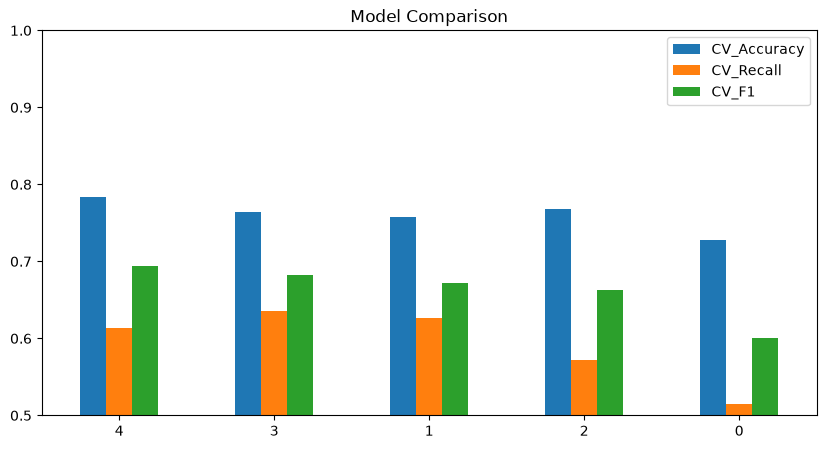

In [87]:
results_df[["CV_Accuracy", "CV_Recall", "CV_F1"]].plot(kind="bar", figsize=(10, 5))
plt.title("Model Comparison")
plt.ylim(0.5, 1)
plt.xticks(rotation=0)
plt.show()

- BEST Model

In [88]:
best_name = results_df.iloc[0]["Model"]
best_model = models[best_name]
print("Best model:", best_name)

Best model: xgb_model


In [89]:
y_pred = best_model.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["Safe (0)", "At Risk (1)"]))

              precision    recall  f1-score   support

    Safe (0)       0.78      0.90      0.83      3077
 At Risk (1)       0.80      0.61      0.70      2036

    accuracy                           0.79      5113
   macro avg       0.79      0.76      0.77      5113
weighted avg       0.79      0.79      0.78      5113



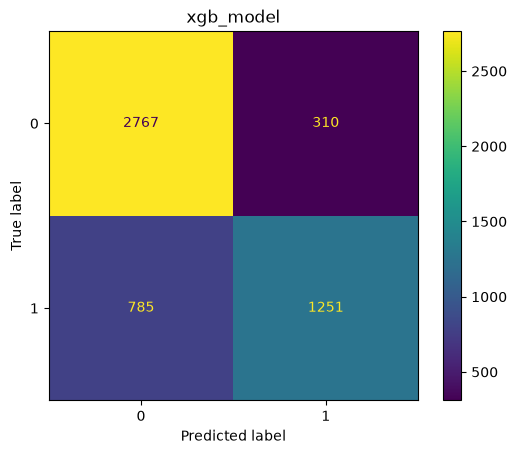

In [90]:
ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test)
plt.title(best_name)
plt.show()

- Hyperparameters Tuned in all Models

In [91]:
from scipy.stats import randint
from sklearn.model_selection import RandomizedSearchCV

param_grids = {
    "Logistic Regression": {"model__C": [0.01, 0.1, 1, 10, 100]},
    "KNN": {"model__n_neighbors": [3, 5, 7, 11, 15, 21]},
    "Decision Tree": {"max_depth": [3, 5, 7, 10, None],"min_samples_leaf": [1, 10, 30, 50]},
    "Random Forest": {"n_estimators": [100, 200, 300],"max_depth": [5, 10, 15, None],"min_samples_leaf": randint(1, 6),
                        "min_samples_split": randint(2, 11),
                        "max_features": ["sqrt", "log2"],"class_weight":["balanced","balanced_subsample"]},
    "xgb_model": {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [3, 4, 5, 6, 8],
    'learning_rate': [0.01, 0.03, 0.05, 0.1, 0.2],
    'min_child_weight': [1, 3, 5, 7],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.8, 0.9, 1.0],
    'gamma': [0, 0.1, 0.2, 0.5],
    'reg_alpha': [0, 0.01, 0.1, 1],
    'reg_lambda': [1, 2, 5, 10]
}}
scoring = {'accuracy':'accuracy','precision':'precision',  'recall':'recall',  'f1':'f1'}
search = RandomizedSearchCV(
    estimator=best_model,
    param_distributions=param_grids[best_name],
    n_iter=50,
    cv=cv,
    scoring=scoring,
    refit="f1",
    n_jobs=-1,
    random_state=42,
    verbose=1
)

search.fit(X_train, y_train)
tuned_model = search.best_estimator_
print("Best model:", best_name)
print("Best parameters:", search.best_params_)
print("Best f1:", round(search.best_score_, 4))

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best model: xgb_model
Best parameters: {'subsample': 0.9, 'reg_lambda': 10, 'reg_alpha': 1, 'n_estimators': 500, 'min_child_weight': 3, 'max_depth': 6, 'learning_rate': 0.05, 'gamma': 0.1, 'colsample_bytree': 1.0}
Best f1: 0.6988


In [92]:
from sklearn.model_selection import cross_val_predict
train_probs = cross_val_predict(tuned_model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

In [93]:

threshold_results = []
for threshold in [0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:
    predictions = (train_probs >= threshold).astype(int)
    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_train, predictions, zero_division=0),
        "Recall": recall_score(y_train, predictions, zero_division=0),
        "F1": f1_score(y_train, predictions, zero_division=0)
    })
threshold_df = pd.DataFrame(threshold_results)
display(threshold_df.round(3))

,Threshold,Precision,Recall,F1
0,0.25,0.591,0.841,0.694
1,0.30,0.636,0.796,0.707
2,0.35,0.680,0.749,0.713
3,0.40,0.720,0.709,0.715
4,0.45,0.751,0.669,0.708
5,0.50,0.784,0.630,0.699


In [94]:
chosen_threshold = 0.35

In [95]:
tuned_model.fit(X_train,y_train)
tuned_probs = tuned_model.predict_proba(X_test)[:,1]

In [96]:
final_pred = (tuned_probs >= chosen_threshold).astype(int)
print(classification_report(y_test, final_pred, target_names=["Safe (0)", "At Risk (1)"]))

              precision    recall  f1-score   support

    Safe (0)       0.82      0.77      0.80      3077
 At Risk (1)       0.69      0.75      0.72      2036

    accuracy                           0.76      5113
   macro avg       0.76      0.76      0.76      5113
weighted avg       0.77      0.76      0.77      5113



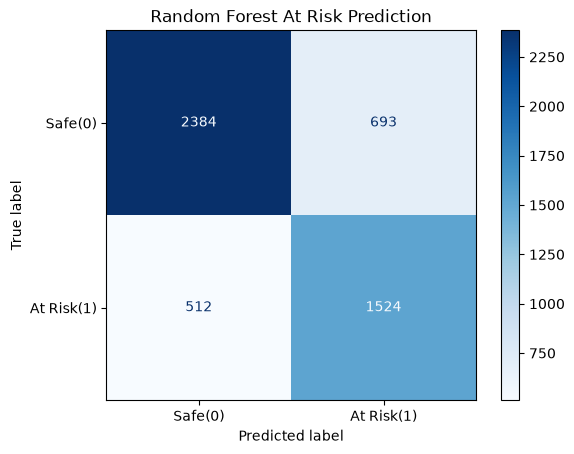

In [97]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, final_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=["Safe(0)","At Risk(1)"])
disp.plot(cmap="Blues")
plt.title("Random Forest At Risk Prediction")
plt.show()

In [98]:
roc_auc = roc_auc_score(y_test, tuned_probs)
print("Test ROC_AUC:", round(roc_auc,4))

Test ROC_AUC: 0.8466


- Feature importance

In [99]:
importance = tuned_model.feature_importances_
feature_importance = pd.DataFrame({"Feature": X_train.columns,"Importance": importance})
feature_importance = feature_importance.sort_values(by="Importance",ascending=False)
print(feature_importance.head(15))

                Feature  Importance
1             avg_score    0.432185
0  num_assessments_done    0.210419
3        weighted_score    0.117099
4      late_submissions    0.085989
5           active_days    0.079791
2             min_score    0.074516


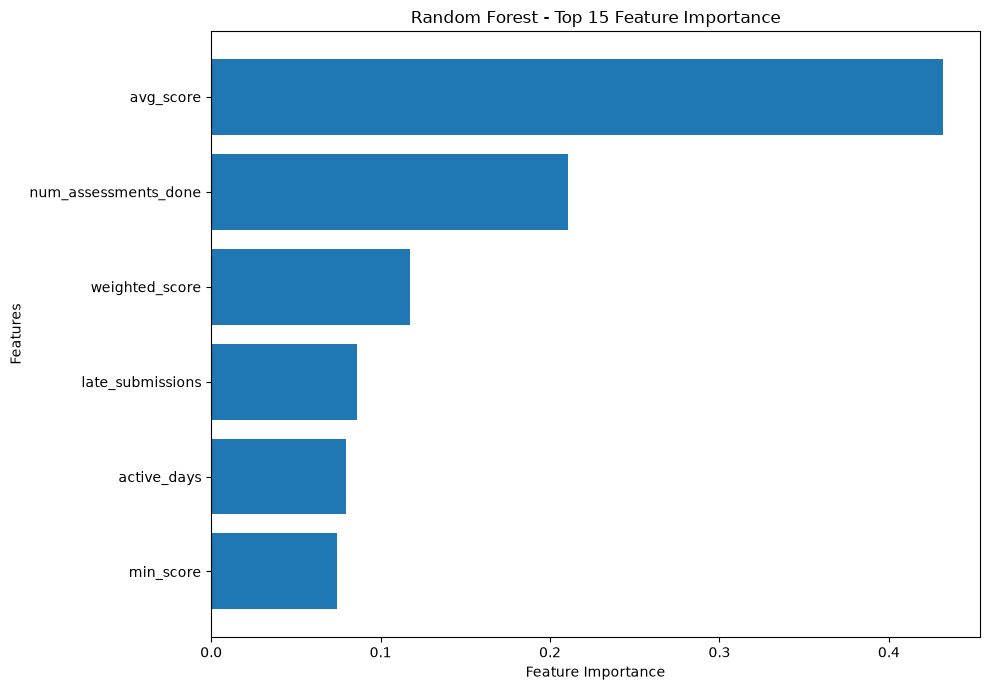

In [100]:
top_features = feature_importance.head(15).sort_values(by="Importance")
plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"],top_features["Importance"])
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Random Forest - Top 15 Feature Importance")
plt.tight_layout()
plt.show()

In [101]:
import joblib
joblib.dump(tuned_model, "best_model.pkl")
print("Model saved")

Model saved
